# Detección de objetos 3D en nubes de puntos LiDAR con SECOND (KITTI)

**Proyecto final — Electiva de Ingeniería de Software, Universidad de San Buenaventura Cali**
Autor: Juan Pablo Isaziga Benavides · Docente: Carlos Mario Paredes

Este notebook reúne el código y los resultados del informe técnico:

1. Entorno de ejecución.
2. Datos: partición y análisis exploratorio de KITTI.
3. Modelo: configuración de SECOND y número de parámetros.
4. Entrenamiento propio (80 épocas) y curva de pérdida.
5. Evaluación en validación (AP con 40 y 11 umbrales) y comparación con los pesos preentrenados de OpenPCDet y con el artículo original.
6. Exhaustividad por franja de distancia.
7. Ejemplos cualitativos en vista de pájaro.

**Cómo ejecutarlo.** Requiere OpenPCDet instalado (ver `README.md` del repositorio) y KITTI en `OpenPCDet/data/kitti`, con los `kitti_infos_*.pkl` ya generados. El entrenamiento tarda unas 7 horas en una RTX 5060, así que por defecto (`ENTRENAR = False`) el notebook lee el registro del entrenamiento que se ejecutó con exactamente el comando que aparece en la sección 4. Las evaluaciones (`test.py`, unos 25 minutos en total) se ejecutaron desde este mismo notebook con `EVALUAR = True` el 17 de noviembre de 2026, y sus registros completos quedaron guardados en `resultados/final/eval_*.txt`. Por defecto (`EVALUAR = False`) el notebook lee esos registros, porque repetir la evaluación en GPU puede mover algunas cifras en la segunda decimal por el no determinismo de ciertas operaciones; con `EVALUAR = True` se vuelven a ejecutar.

In [1]:
import os, sys, re, shutil, subprocess, pickle, platform, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, display

# --- Rutas -----------------------------------------------------------------
PROY = Path.cwd().parent                                   # raiz del repositorio
OPCD = Path(os.environ.get("OPENPCDET", "/root/proyecto_lidar/OpenPCDet"))
TOOLS = OPCD / "tools"
CFG = "cfgs/kitti_models/second.yaml"                      # relativo a TOOLS
TAG = "entrenamiento_propio"
SALIDA = OPCD / "output/kitti_models/second" / TAG          # salida de train.py
CKPT_PRE = PROY / "checkpoints/second.pth"                 # pesos de OpenPCDet
RES = PROY / "resultados/final"
RES.mkdir(parents=True, exist_ok=True)

# --- Opciones --------------------------------------------------------------
ENTRENAR = False          # True: vuelve a entrenar 80 epocas (~7 h)
EVALUAR = False           # True: vuelve a ejecutar test.py (~25 min); False: lee los registros guardados
EPOCAS_EVAL = [20, 40, 60, 80]
UMBRAL = 0.3              # score minimo para figuras y analisis por distancia
ESCENAS = ["000201", "000124"]

# Los scripts propios del repositorio se copian a OpenPCDet/tools, porque
# OpenPCDet resuelve la ruta de los datos relativa a esa carpeta.
for f in ["eda_kitti.py", "bev_predicciones.py", "analisis_distancia.py", "tabla_resultados.py"]:
    shutil.copy(PROY / "scripts" / f, TOOLS / f)
sys.path.insert(0, str(TOOLS))
os.chdir(TOOLS)   # OpenPCDet usa rutas relativas a tools (p. ej. ../data/kitti)
os.environ["NUMBA_CUDA_USE_NVIDIA_BINDING"] = "1"   # necesario en la RTX 5060 (ver README)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})


def correr(cmd, log=None):
    # Ejecuta un comando desde OpenPCDet/tools y muestra el final de su salida.
    print("$", " ".join(cmd))
    r = subprocess.run(cmd, cwd=TOOLS, capture_output=True, text=True)
    salida = r.stdout + r.stderr
    if log:
        Path(log).write_text(salida)
    if r.returncode != 0:
        print(salida[-3000:])
        raise RuntimeError(f"fallo con codigo {r.returncode}")
    return salida

print("Repositorio:", PROY)
print("OpenPCDet:  ", OPCD)

Repositorio: /mnt/c/Users/JUAN  I/Escritorio/Electiva de ing sw/proyecto_lidar
OpenPCDet:   /root/proyecto_lidar/OpenPCDet


## 1. Entorno de ejecución

In [2]:
import torch, spconv, numba, pcdet
gpu = subprocess.run(["nvidia-smi", "--query-gpu=name,driver_version,memory.total",
                      "--format=csv,noheader"], capture_output=True, text=True).stdout.strip()
commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], cwd=OPCD,
                        capture_output=True, text=True).stdout.strip()
entorno = {
    "GPU (nombre, controlador, memoria)": gpu,
    "Sistema": platform.platform(),
    "Python": platform.python_version(),
    "PyTorch": torch.__version__,
    "CUDA (PyTorch)": torch.version.cuda,
    "spconv": spconv.__version__,
    "numba": numba.__version__,
    "OpenPCDet": f"{pcdet.__version__} (commit {commit})",
}
for k, v in entorno.items():
    print(f"{k:<36} {v}")
(RES / "entorno.txt").write_text("\n".join(f"{k}: {v}" for k, v in entorno.items()) + "\n")
assert torch.cuda.is_available()

GPU (nombre, controlador, memoria)   NVIDIA GeForce RTX 5060, 610.88, 8151 MiB
Sistema                              Linux-6.18.58.1-microsoft-standard-WSL2-x86_64-with-glibc2.35
Python                               3.9.25
PyTorch                              2.7.1+cu128
CUDA (PyTorch)                       12.8
spconv                               2.3.8
numba                                0.60.0
OpenPCDet                            0.6.0+233f849 (commit 233f849)


## 2. Datos

Se usa la partición de Chen et al. (2015): 3 712 escenas para entrenamiento y 3 769 para validación, tomadas del conjunto de entrenamiento de KITTI (7 481 escenas con etiquetas).

In [3]:
KITTI = OPCD / "data/kitti"
train_ids = (KITTI / "ImageSets/train.txt").read_text().split()
val_ids = (KITTI / "ImageSets/val.txt").read_text().split()
print("train:", len(train_ids), " val:", len(val_ids), " interseccion:", len(set(train_ids) & set(val_ids)))
assert len(train_ids) == 3712 and len(val_ids) == 3769
print("planos de calzada (aumentacion):", len(list((KITTI / "training/planes").glob("*.txt"))))

train: 3712  val: 3769  interseccion: 0


planos de calzada (aumentacion): 7481


### 2.1 Análisis exploratorio

`eda_kitti.py` cuenta los objetos por clase y por nivel de dificultad en las 7 481 escenas etiquetadas, y la mediana de puntos LiDAR dentro de cada caja por franja de distancia.

Escenas encontradas: 7481

Objetos anotados (sin DontCare): 40570

Clase                 Conteo        %
Car                    28742    70.8
Pedestrian              4487    11.1
Van                     2914     7.2
Cyclist                 1627     4.0
Truck                   1094     2.7
Misc                     973     2.4
Tram                     511     1.3
Person_sitting           222     0.5

Clase             Facil   Moderado   Dificil
Car                5971       9739      6006
Pedestrian         2310       1259       707
Cyclist             654        444        96

Puntos LiDAR por objeto (mediana), 7481 escenas
Clase               0-20 m     20-40 m     40-70 m
Car                    722          86          17
Pedestrian             217          41          11
Cyclist                215          45          16
Objetos usados por franja:
Car                   9466       12044        6741
Pedestrian            2905        1352         222
Cyclist                627         7

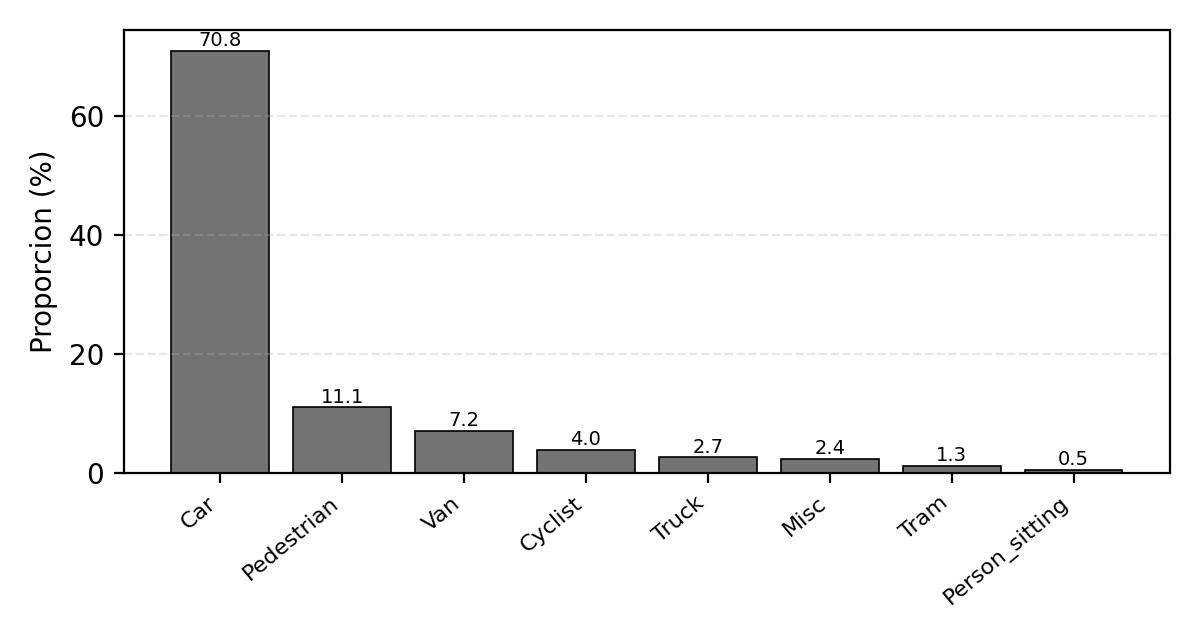

In [4]:
d_eda = RES / "eda"
d_eda.mkdir(exist_ok=True)
r = subprocess.run([sys.executable, str(TOOLS / "eda_kitti.py"), "--root", str(KITTI / "training"),
                    "--muestras-puntos", "7481"], cwd=d_eda, capture_output=True, text=True)
print(r.stdout[-4000:], r.stderr[-2000:])
(d_eda / "eda_consola.txt").write_text(r.stdout)
display(Image(str(d_eda / "distribucion_clases.png"), width=550))

## 3. Modelo: configuración de SECOND

In [5]:
from pcdet.config import cfg, cfg_from_yaml_file
from pcdet.datasets.kitti.kitti_dataset import KittiDataset
from pcdet.models import build_network
from pcdet.utils import common_utils

os.chdir(TOOLS)
cfg_from_yaml_file(CFG, cfg)
dc, mc, oc = cfg.DATA_CONFIG, cfg.MODEL, cfg.OPTIMIZATION
print("Clases:", cfg.CLASS_NAMES)
print("Rango de la nube [x0,y0,z0,x1,y1,z1]:", dc.POINT_CLOUD_RANGE)
vox = [p for p in dc.DATA_PROCESSOR if p.NAME == "transform_points_to_voxels"][0]
print("Tamano de voxel:", vox.VOXEL_SIZE, "| max puntos/voxel:", vox.MAX_POINTS_PER_VOXEL,
      "| max voxeles (train/test):", vox.MAX_NUMBER_OF_VOXELS)
for a in mc.DENSE_HEAD.ANCHOR_GENERATOR_CONFIG:
    print(f"Ancla {a['class_name']:<11} tamano {a['anchor_sizes'][0]}  z={a['anchor_bottom_heights'][0]}"
          f"  IoU +/-: {a['matched_threshold']}/{a['unmatched_threshold']}")
print("Optimizador:", oc.OPTIMIZER, "| LR:", oc.LR, "| epocas:", oc.NUM_EPOCHS,
      "| lote por GPU:", oc.BATCH_SIZE_PER_GPU, "| weight decay:", oc.WEIGHT_DECAY)
print("Pesos de la perdida:", dict(mc.DENSE_HEAD.LOSS_CONFIG.LOSS_WEIGHTS))

logger = common_utils.create_logger()
ds_val = KittiDataset(dataset_cfg=dc, class_names=cfg.CLASS_NAMES, training=False, logger=logger)
modelo = build_network(model_cfg=mc, num_class=len(cfg.CLASS_NAMES), dataset=ds_val)
n_par = sum(p.numel() for p in modelo.parameters())
print(f"Parametros entrenables: {n_par:,}".replace(",", "."))
for nombre, m in modelo.named_children():
    if m is not None:
        print(f"  {nombre:<18} {sum(p.numel() for p in m.parameters()):>12,}".replace(",", "."))
del modelo

2026-11-17 19:00:35,251   INFO  Loading KITTI dataset


2026-11-17 19:00:35,372   INFO  Total samples for KITTI dataset: 3769


Clases: ['Car', 'Pedestrian', 'Cyclist']
Rango de la nube [x0,y0,z0,x1,y1,z1]: [0, -40, -3, 70.4, 40, 1]
Tamano de voxel: [0.05, 0.05, 0.1] | max puntos/voxel: 5 | max voxeles (train/test): {'train': 16000, 'test': 40000}
Ancla Car         tamano [3.9, 1.6, 1.56]  z=-1.78  IoU +/-: 0.6/0.45
Ancla Pedestrian  tamano [0.8, 0.6, 1.73]  z=-0.6  IoU +/-: 0.5/0.35
Ancla Cyclist     tamano [1.76, 0.6, 1.73]  z=-0.6  IoU +/-: 0.5/0.35
Optimizador: adam_onecycle | LR: 0.003 | epocas: 80 | lote por GPU: 4 | weight decay: 0.01
Pesos de la perdida: {'cls_weight': 1.0, 'loc_weight': 2.0, 'dir_weight': 0.2, 'code_weights': [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]}


Parametros entrenables: 5.325.576
  vfe                           0
  backbone_3d             711.872
  map_to_bev_module             0
  backbone_2d           4.576.768
  dense_head               36.936


## 4. Entrenamiento propio

Configuración oficial de OpenPCDet sin cambios: 80 épocas, lote de 4, Adam con política de un ciclo (tasa máxima 0,003) y semilla fija. Se entrenó desde cero sobre las 3 712 escenas de `train`. Comando ejecutado en `OpenPCDet/tools`:

In [6]:
cmd_train = [sys.executable, "train.py", "--cfg_file", CFG, "--batch_size", "4", "--epochs", "80",
             "--extra_tag", TAG, "--max_ckpt_save_num", "80", "--fix_random_seed"]
print(" ".join(cmd_train[1:]))
if ENTRENAR:
    correr(cmd_train, log=RES / "train_consola.txt")

train.py --cfg_file cfgs/kitti_models/second.yaml --batch_size 4 --epochs 80 --extra_tag entrenamiento_propio --max_ckpt_save_num 80 --fix_random_seed


Registro: train_20261116-164427.log
Iteraciones por epoca: 928 | epocas registradas: 80 | duracion: 0 days 06:28:52
Perdida media por epoca (primeras y ultimas):
epoca
1     1.100
2     0.781
5     0.622
10    0.562
20    0.513
40    0.430
60    0.337
70    0.297
80    0.280


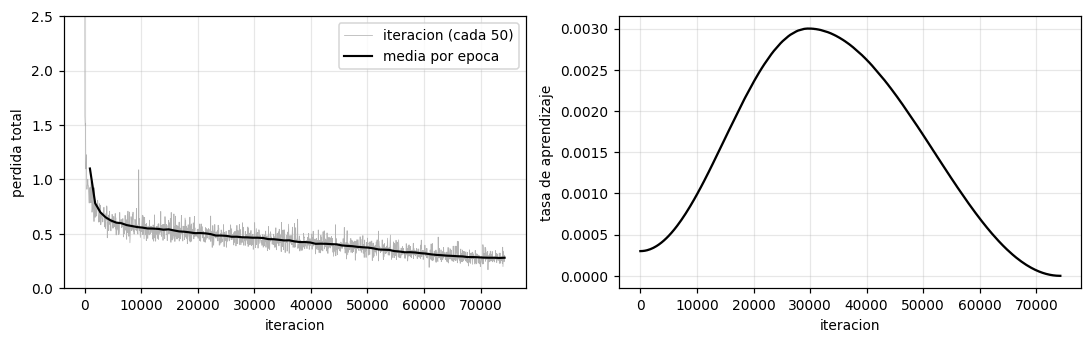

In [7]:
log_train = sorted(SALIDA.glob("train_*.log"))[-1]
patron = re.compile(r"^(\S+ \S+),\d+\s+INFO\s+Train:\s+(\d+)/\d+.*?\[\s*(\d+)/(\d+).*?"
                    r"Loss: ([\d.]+) \(([\d.]+)\)\s+LR: ([\d.e+-]+)")
filas = []
for linea in log_train.read_text().splitlines():
    m = patron.match(linea)
    if m:
        t, ep, it, n_it, loss, loss_media, lr = m.groups()
        filas.append(dict(hora=pd.Timestamp(t), epoca=int(ep), iter_epoca=int(it), iters=int(n_it),
                          loss=float(loss), loss_media=float(loss_media), lr=float(lr)))
tr = pd.DataFrame(filas)
tr["iter"] = (tr.epoca - 1) * tr.iters + tr.iter_epoca
por_epoca = tr.groupby("epoca").last()[["loss_media", "lr"]]
duracion = tr.hora.iloc[-1] - tr.hora.iloc[0]
print("Registro:", log_train.name)
print(f"Iteraciones por epoca: {tr.iters.iloc[0]} | epocas registradas: {tr.epoca.max()}"
      f" | duracion: {duracion}")
print("Perdida media por epoca (primeras y ultimas):")
print(por_epoca.loss_media.loc[[e for e in [1, 2, 5, 10, 20, 40, 60, 70, 80]
                                if e in por_epoca.index]].round(3).to_string())
shutil.copy(log_train, RES / "log_entrenamiento.txt")
por_epoca.to_csv(RES / "perdida_por_epoca.csv")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(tr.iter, tr.loss, lw=0.5, color="0.7", label="iteracion (cada 50)")
ax[0].plot(por_epoca.index * tr.iters.iloc[0], por_epoca.loss_media, color="k", lw=1.4, label="media por epoca")
ax[0].set_xlabel("iteracion"); ax[0].set_ylabel("perdida total"); ax[0].set_ylim(0, 2.5)
ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(tr.iter, tr.lr, color="k")
ax[1].set_xlabel("iteracion"); ax[1].set_ylabel("tasa de aprendizaje"); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.savefig(RES / "curva_entrenamiento.png", dpi=200); plt.show()

## 5. Evaluación en el conjunto de validación

Se evalúa con `test.py` (código oficial de KITTI incluido en OpenPCDet) el punto de control de cada 20 épocas, para ver la convergencia. **El resultado que se reporta es el de la época 80** (el modelo final), sin elegir la mejor época sobre validación, para no sesgar la cifra a favor. Para comparar se evalúan también los pesos preentrenados que publica OpenPCDet.

In [8]:
from tabla_resultados import leer as leer_ap


def evaluar(ckpt, tag, nombre_log):
    cmd = [sys.executable, "test.py", "--cfg_file", CFG, "--batch_size", "4",
           "--ckpt", str(ckpt), "--extra_tag", tag]
    correr(cmd, log=RES / nombre_log)
    return RES / nombre_log


logs = {}
for ep in EPOCAS_EVAL:
    ck = SALIDA / "ckpt" / f"checkpoint_epoch_{ep}.pth"
    nombre = f"eval_propio_epoca{ep}.txt"
    logs[ep] = evaluar(ck, TAG, nombre) if EVALUAR else RES / nombre
    print(f"epoca {ep}: {'evaluada' if EVALUAR else 'registro leido'} -> {logs[ep].name}")
log_pre = evaluar(CKPT_PRE, "preentrenado", "eval_preentrenado.txt") if EVALUAR else RES / "eval_preentrenado.txt"
print(f"preentrenado: {'evaluado' if EVALUAR else 'registro leido'} -> {log_pre.name}")
for f in list(logs.values()) + [log_pre]:
    fecha = re.search(r"^(\d{4}-\d\d-\d\d \d\d:\d\d:\d\d),", f.read_text(), re.M).group(1)
    print(f"  {f.name}: generado {fecha}")

epoca 20: registro leido -> eval_propio_epoca20.txt
epoca 40: registro leido -> eval_propio_epoca40.txt
epoca 60: registro leido -> eval_propio_epoca60.txt
epoca 80: registro leido -> eval_propio_epoca80.txt
preentrenado: registro leido -> eval_preentrenado.txt
  eval_propio_epoca20.txt: generado 2026-11-17 09:07:32
  eval_propio_epoca40.txt: generado 2026-11-17 09:10:03
  eval_propio_epoca60.txt: generado 2026-11-17 09:12:24
  eval_propio_epoca80.txt: generado 2026-11-17 09:14:34
  eval_preentrenado.txt: generado 2026-11-17 09:16:46


In [9]:
CLASES = ["Car", "Pedestrian", "Cyclist"]
NIVELES = ["Facil", "Moderado", "Dificil"]


def tabla(log, var="AP_R40"):
    ap = leer_ap(log)
    filas = {}
    for c in CLASES:
        filas[c] = ap[(c, var, "3d")] + ap[(c, var, "bev")]
    cols = pd.MultiIndex.from_product([["AP_3D", "AP_BEV"], NIVELES])
    return pd.DataFrame.from_dict(filas, orient="index", columns=cols)


def tiempo(log):
    m = re.search(r"sec_per_example: ([\d.]+)", Path(log).read_text())
    return float(m.group(1))


propio = tabla(logs[80])
pre = tabla(log_pre)
print("SECOND, entrenamiento propio (epoca 80) - AP R40 (%)")
display(propio.round(2))
print("SECOND, pesos preentrenados de OpenPCDet - AP R40 (%)")
display(pre.round(2))
print("Diferencia propio - preentrenado (puntos)")
display((propio.round(2) - pre.round(2)).round(2))
print(f"Tiempo de inferencia por escena: propio {tiempo(logs[80]):.4f} s, preentrenado {tiempo(log_pre):.4f} s")
propio.round(2).to_csv(RES / "ap_r40_propio.csv")
pre.round(2).to_csv(RES / "ap_r40_preentrenado.csv")

SECOND, entrenamiento propio (epoca 80) - AP R40 (%)


AP_3D                  AP_BEV                 
            Facil Moderado Dificil  Facil Moderado Dificil
Car         89.50    81.09   78.21  91.93    88.21   87.27
Pedestrian  55.79    51.23   46.90  60.52    56.16   52.22
Cyclist     81.63    65.93   61.91  85.33    69.85   66.00

SECOND, pesos preentrenados de OpenPCDet - AP R40 (%)


AP_3D                  AP_BEV                 
            Facil Moderado Dificil  Facil Moderado Dificil
Car         90.55    81.61   78.60  92.42    88.55   87.65
Pedestrian  55.95    51.15   46.17  60.74    56.57   52.14
Cyclist     82.96    66.73   62.78  88.05    71.16   66.89

Diferencia propio - preentrenado (puntos)


AP_3D                  AP_BEV                 
           Facil Moderado Dificil  Facil Moderado Dificil
Car        -1.05    -0.52   -0.39  -0.49    -0.34   -0.38
Pedestrian -0.16     0.08    0.73  -0.22    -0.41    0.08
Cyclist    -1.33    -0.80   -0.87  -2.72    -1.31   -0.89

Tiempo de inferencia por escena: propio 0.0283 s, preentrenado 0.0283 s


### 5.1 Comparación con la literatura (11 umbrales)

El artículo de SECOND (Yan et al., 2018) y la tabla de OpenPCDet reportan la AP con 11 umbrales, así que la comparación con ellos se hace con esa variante.

In [10]:
PAPER_R11_CAR = {"AP_3D": [87.43, 76.48, 69.10], "AP_BEV": [89.96, 87.07, 79.66]}   # Yan et al. 2018, val
README_R11_MOD = {"Car": 78.62, "Pedestrian": 52.98, "Cyclist": 67.15}               # OpenPCDet, val

p11, pre11 = tabla(logs[80], "AP").round(2), tabla(log_pre, "AP").round(2)
comp = pd.DataFrame({
    "Yan et al. 2018": PAPER_R11_CAR["AP_3D"] + PAPER_R11_CAR["AP_BEV"],
    "Preentrenado": list(pre11.loc["Car"]),
    "Propio": list(p11.loc["Car"]),
}, index=pd.MultiIndex.from_product([["AP_3D", "AP_BEV"], NIVELES]))
comp["Propio - paper"] = (comp["Propio"] - comp["Yan et al. 2018"]).round(2)
print("Automovil, AP con 11 umbrales (%)")
display(comp)
mod = pd.DataFrame({"README OpenPCDet": README_R11_MOD,
                    "Preentrenado": pre11[("AP_3D", "Moderado")],
                    "Propio": p11[("AP_3D", "Moderado")]})
mod["Propio - README"] = (mod["Propio"] - mod["README OpenPCDet"]).round(2)
print("AP_3D moderado con 11 umbrales (%)")
display(mod)
comp.to_csv(RES / "comparacion_paper_r11.csv")
mod.to_csv(RES / "comparacion_readme_r11.csv")

Automovil, AP con 11 umbrales (%)


Yan et al. 2018  Preentrenado  Propio  Propio - paper
AP_3D  Facil               87.43         88.61   87.77            0.34
       Moderado            76.48         78.62   78.19            1.71
       Dificil             69.10         77.20   76.95            7.85
AP_BEV Facil               89.96         90.01   89.75           -0.21
       Moderado            87.07         87.91   87.57            0.50
       Dificil             79.66         86.46   85.99            6.33

AP_3D moderado con 11 umbrales (%)


,README OpenPCDet,Preentrenado,Propio,Propio - README
Car,78.62,78.62,78.19,-0.43
Pedestrian,52.98,52.99,52.66,-0.32
Cyclist,67.15,67.13,65.85,-1.30


### 5.2 Convergencia: AP en validación cada 20 épocas

,Car,Pedestrian,Cyclist
epoca,,,
20,71.99,39.48,59.22
40,68.49,43.71,62.31
60,78.59,44.29,65.36
80,81.09,51.23,65.93


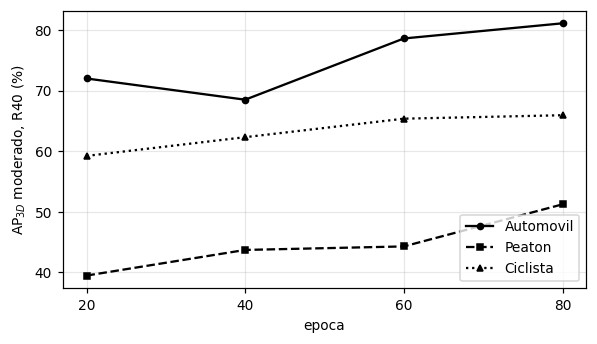

In [11]:
conv = pd.DataFrame({ep: tabla(logs[ep])[("AP_3D", "Moderado")] for ep in EPOCAS_EVAL}).T.round(2)
conv.index.name = "epoca"
display(conv)
conv.to_csv(RES / "ap3d_moderado_por_epoca.csv")
fig, ax = plt.subplots(figsize=(5.5, 3.2))
nombres_es = {"Car": "Automovil", "Pedestrian": "Peaton", "Cyclist": "Ciclista"}
for c, est in zip(CLASES, ["-o", "--s", ":^"]):
    ax.plot(conv.index, conv[c], est, color="k", ms=4, label=nombres_es[c])
ax.set_xlabel("epoca"); ax.set_ylabel("AP$_{3D}$ moderado, R40 (%)")
ax.set_xticks(EPOCAS_EVAL); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.savefig(RES / "ap_por_epoca.png", dpi=200); plt.show()

## 6. Exhaustividad por franja de distancia

Para cada objeto real de validación que entra en la evaluación oficial (fácil, moderado o difícil) se comprueba si alguna predicción de su clase con score ≥ 0,3 lo cubre con IoU 3D ≥ 0,7 (automóvil) o ≥ 0,5 (peatón, ciclista). Los objetos se agrupan por la distancia horizontal de su centro al sensor.

,clase,franja,detectados,total,recall_propio,recall_preentrenado
0,Car,0-20 m,3559,3787,93.98,94.22
1,Car,20-40 m,4731,5708,82.88,82.95
2,Car,40-70.4 m,816,1468,55.59,55.45
3,Pedestrian,0-20 m,1080,1538,70.22,68.66
4,Pedestrian,20-40 m,328,562,58.36,54.80
5,Pedestrian,40-70.4 m,9,72,12.50,18.06
6,Cyclist,0-20 m,181,215,84.19,83.72
7,Cyclist,20-40 m,207,290,71.38,74.14
8,Cyclist,40-70.4 m,58,95,61.05,60.00


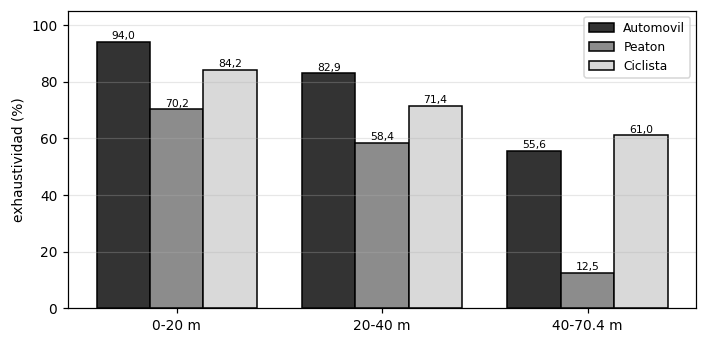

In [12]:
from analisis_distancia import calcular, FRANJAS

with open(KITTI / "kitti_infos_val.pkl", "rb") as f:
    infos_val = pickle.load(f)


def recall_df(result_pkl):
    with open(result_pkl, "rb") as f:
        res = pickle.load(f)
    cuenta = calcular(infos_val, res, UMBRAL)
    filas = []
    for c in CLASES:
        for (a, b), (det, tot) in zip(FRANJAS, cuenta[c]):
            filas.append(dict(clase=c, franja=f"{a}-{b:g} m", detectados=det, total=tot,
                              recall=round(100 * det / tot, 2)))
    return pd.DataFrame(filas)


pkl_propio = SALIDA / "eval/epoch_80/val/default/result.pkl"
pkl_pre = OPCD / "output/kitti_models/second/preentrenado/eval/epoch_no_number/val/default/result.pkl"
dist = recall_df(pkl_propio).merge(recall_df(pkl_pre)[["clase", "franja", "recall"]],
                                   on=["clase", "franja"], suffixes=("_propio", "_preentrenado"))
display(dist)
dist.to_csv(RES / "recall_por_distancia.csv", index=False)

fig, ax = plt.subplots(figsize=(6.5, 3.2))
x = np.arange(len(FRANJAS)); w = 0.26
for k, (c, gris) in enumerate(zip(CLASES, ["0.2", "0.55", "0.85"])):
    v = dist[dist.clase == c].recall_propio.values
    ax.bar(x + (k - 1) * w, v, w, color=gris, edgecolor="k", label=nombres_es[c])
    for xi, vi in zip(x + (k - 1) * w, v):
        ax.text(xi, vi + 1, f"{vi:.1f}".replace(".", ","), ha="center", fontsize=7)
ax.set_xticks(x); ax.set_xticklabels([f"{a}-{b:g} m" for a, b in FRANJAS])
ax.set_ylabel("exhaustividad (%)"); ax.set_ylim(0, 105); ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig(RES / "recall_por_distancia.png", dpi=200); plt.show()

## 7. Ejemplos cualitativos

Vista de pájaro de dos escenas de validación. Verde: anotación real; rojo discontinuo: predicción del modelo propio con score ≥ 0,3. Son las mismas escenas que se mostraron con los pesos preentrenados en el segundo avance.

$ /root/venv/bin/python bev_predicciones.py --cfg_file cfgs/kitti_models/second.yaml --ckpt /root/proyecto_lidar/OpenPCDet/output/kitti_models/second/entrenamiento_propio/ckpt/checkpoint_epoch_80.pth --root ../data/kitti/training --ids 000201 000124 --umbral 0.3


000201: anotaciones
    Car            x=   1.2  y=  -2.9  dist=  3.1  oclusion=0  trunc=1.00
    Car            x=   6.0  y=  -2.9  dist=  6.6  oclusion=1  trunc=0.45
    Car            x=  15.1  y=  -2.1  dist= 15.3  oclusion=0  trunc=0.00
    Cyclist        x=  18.7  y=   4.6  dist= 19.3  oclusion=0  trunc=0.00
    Car            x=  17.8  y=   5.9  dist= 18.7  oclusion=0  trunc=0.00
    Car            x=  22.2  y=  -1.1  dist= 22.2  oclusion=1  trunc=0.00
    Car            x=  34.2  y=   1.3  dist= 34.2  oclusion=0  trunc=0.00
    Car            x=  39.1  y=   9.6  dist= 40.3  oclusion=2  trunc=0.00
    Car            x=  44.0  y=   3.5  dist= 44.1  oclusion=1  trunc=0.00
    Pedestrian     x=  48.3  y=  13.2  dist= 50.0  oclusion=1  trunc=0.00
    Pedestrian     x=  48.1  y=  13.7  dist= 50.0  oclusion=2  trunc=0.00
    Cyclist        x=  20.8  y=   4.2  dist= 21.2  oclusion=0  trunc=0.00
000201: 12 objetos reales (Car/Ped/Cyc), 11 detecciones -> pred_000201.png
    Car         s

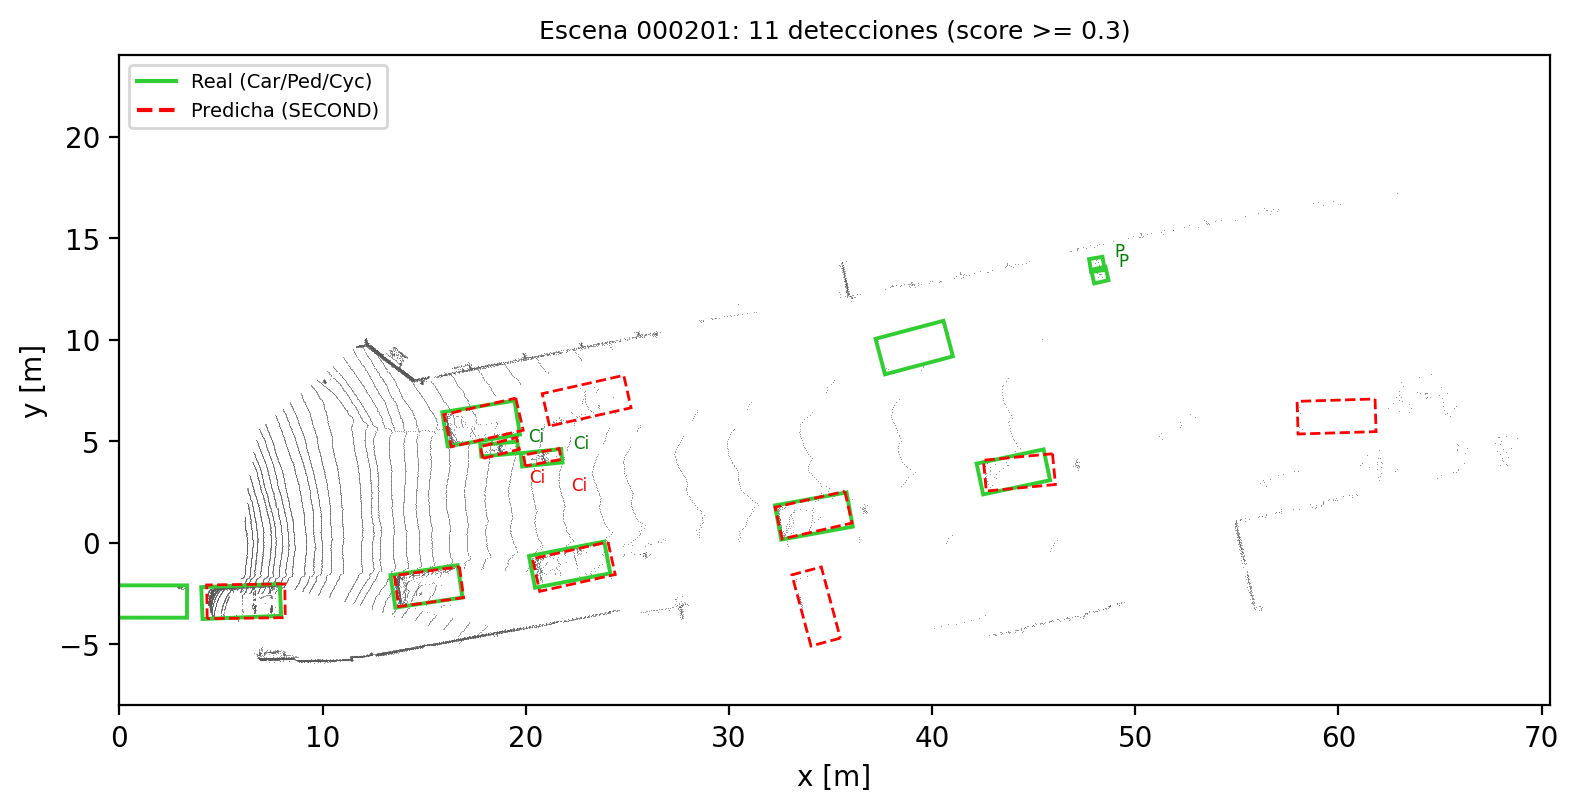

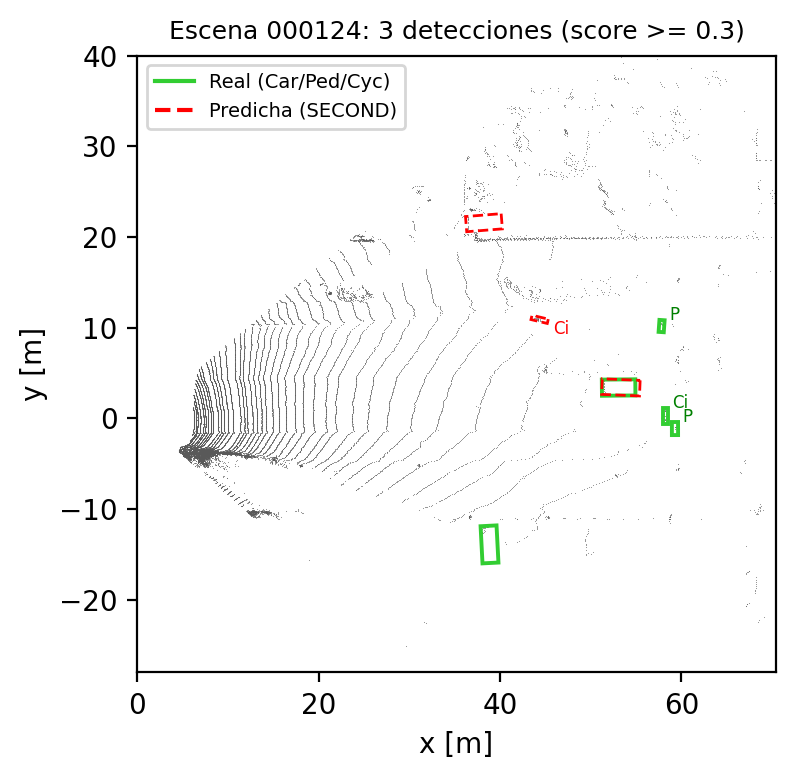

In [13]:
d_fig = RES / "cualitativo"
d_fig.mkdir(exist_ok=True)
ck80 = SALIDA / "ckpt/checkpoint_epoch_80.pth"
salida = correr([sys.executable, "bev_predicciones.py", "--cfg_file", CFG, "--ckpt", str(ck80),
                 "--root", "../data/kitti/training", "--ids", *ESCENAS, "--umbral", str(UMBRAL)])
txt = "\n".join(l for l in salida.splitlines() if l.startswith(("0", "    ")))
print(txt)
(d_fig / "bev_predicciones_consola.txt").write_text(txt + "\n")
for i in ESCENAS:
    shutil.move(str(TOOLS / f"pred_{i}.png"), d_fig / f"pred_{i}.png")
    display(Image(str(d_fig / f"pred_{i}.png"), width=750))

## 8. Resumen de cifras

Cifras derivadas que cita el informe (diferencias, brechas y caídas). Se calculan con `scripts/cifras_informe.py` a partir de las tablas que generó este notebook, redondeadas a dos decimales, de modo que coinciden con lo que se obtiene restando los valores de las tablas.

In [14]:
pr = propio.round(2)
print(f"AP_3D R40 moderado (propio): automovil {pr.loc['Car', ('AP_3D', 'Moderado')]:.2f}, peaton "
      f"{pr.loc['Pedestrian', ('AP_3D', 'Moderado')]:.2f}, ciclista "
      f"{pr.loc['Cyclist', ('AP_3D', 'Moderado')]:.2f}")
print(f"Duracion del entrenamiento: {duracion}\n")
r = subprocess.run([sys.executable, str(PROY / "scripts/cifras_informe.py")], capture_output=True, text=True)
print(r.stdout, r.stderr)

AP_3D R40 moderado (propio): automovil 81.09, peaton 51.23, ciclista 65.93
Duracion del entrenamiento: 0 days 06:28:52



Cifras derivadas para el informe (fuente: CSV de resultados/final)

Propio - preentrenado, AP R40 (puntos)
3d  Car         -1.05 -0.52 -0.39
3d  Pedestrian  -0.16 0.08 0.73
3d  Cyclist     -1.33 -0.80 -0.87
bev Car         -0.49 -0.34 -0.38
bev Pedestrian  -0.22 -0.41 0.08
bev Cyclist     -2.72 -1.31 -0.89
rango de diferencias: -2.72 a 0.73

Brecha automovil - clase, AP_3D R40 moderado
propio       Car - Pedestrian: 29.86
propio       Car - Cyclist: 15.16
preentrenado Car - Pedestrian: 30.46
preentrenado Car - Cyclist: 14.88

Caida facil -> dificil, AP_3D R40 (propio)
Car         11.29
Pedestrian  8.89
Cyclist     19.72
Diferencia AP_BEV - AP_3D moderado (propio)
Car         7.12
Pedestrian  4.93
Cyclist     3.92

Convergencia AP_3D moderado: cambio entre evaluaciones
epoca 20->40: Car -3.50 Pedestrian 4.23 Cyclist 3.09
epoca 40->60: Car 10.10 Pedestrian 0.58 Cyclist 3.05
epoca 60->80: Car 2.50 Pedestrian 6.94 Cyclist 0.57

Recall por distancia (propio): caida 0-20 m -> 40-70,4 m y dif